In [6]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import AlgCoM

In [7]:
#X,Y must be a box
Y=[(0,4*np.pi)]
X=[(-1,1),(-1,1),(0,100)]
norm=2
#DCP of f following cxvpy rules
def fcp(x):
    return x[2]
    
#DCP of g following cxvpy rules
def gcp(x,y):
    return cp.pnorm(x[0:2]-p(y),norm)-x[2]
    
def g(x,y):
    return np.linalg.norm(x[0:2]-p(y),norm)-x[2]   
    
#Curves
def p(y):
    return np.cos(y)[0],2*np.sin(y)[0]



def p(y):
    c=4.5
    d=4.5
    return c*np.cos(y)[0]-np.cos(c*y)[0],d*np.sin(y)[0]-np.sin(d*y)[0]

#def p(y):
    #c=40
    #return c*np.cos(y)[0]-np.cos(c*y)[0],np.sin(20*y)[0]+c*np.sin(y)[0]-np.sin(c*y)[0]


def circle(c,r,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    for i in range(N):
        x[i]=c[0]+r*np.cos(t[i])
        y[i]=c[0]+r*np.sin(t[i])
    return x,y

def square(c,r,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    for i in range(N):
        x[i]=c[0]+r*np.cos(t[i])
        y[i]=c[0]+r*np.sin(t[i])
    return x,y


In [8]:
x0=np.array([0,0,0])
y0=np.array([0])

In [9]:
res=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y)

Time 0.16556715965270996
Time upper problem 0.12084364891052246
Time lower problem 0.0447235107421875
Feasibility 2.725684478122048e-08
Final rho 1.5
Rho increases 1
Optimal value 5.500000014449941
Value function call 8


In [10]:
res=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 3.4476559162139893
Time upper problem 3.373366355895996
Time lower problem 0.07428956031799316
Feasibility 9.958092075379454e-07
Optimal value 5.500001089583189
Value function call 34


In [11]:
res=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1000)

Time 0.24905991554260254
Time upper problem 0.17399239540100098
Time lower problem 0.07469773292541504
Feasibility -9.309424999770499e-07
Optimal value 5.5000000010850645
Optimality cuts 3
Feasibility cuts 7
Value function calls 10


In [12]:
res=AlgBF(x0,y0,fcp,gcp,g,X,Y)

Time 0.19919157028198242
Time upper problem 0.13679790496826172
Time lower problem 0.0623936653137207
Feasibility 1.2924714631878942e-08
Optimal value 5.500000007631658
Value function call 7


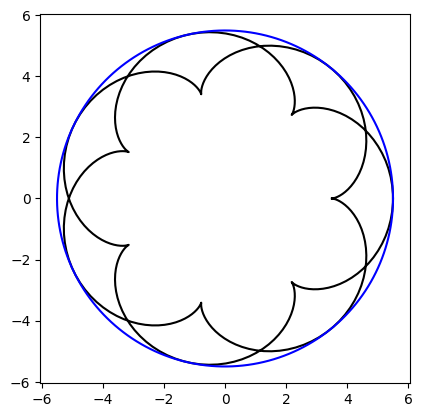

In [26]:
N = 400
t = np.linspace(Y[0][0], Y[0][1], N)
x=np.ones(N)
y=np.ones(N)
for i in range(N):
    x[i], y[i]= p(np.array([t[i]]))

fig, ax = plt.subplots()
ax.plot(x, y, "k")
ax.set(aspect=1)

center=res[0][0:2]
radius=res[0][2]

x1,y1=circle(center,radius,N)
ax.plot(x1, y1, "b")

In [4]:
cp.sum([1,2])

3